# [1] Problem

# Dry Bean Classification and Clustering

# project Description

This project aims to analyze dry bean data to identify and distinguish different types of dry beans based on their physical characteristics. Using attributes that describe their shape, size, and other properties, classification techniques are applied to categorize beans into their corresponding types.

In addition, clustering methods are used to group dry beans with similar characteristics and discover patterns within the dataset. By combining these approaches, the project provides meaningful insights into different dry bean types and demonstrates how data mining techniques can support classification and pattern discovery.

# Project Goal:

The primary objective of this project is to develop predictive techniques that classify different types of dry beans based on their physical characteristics and use clustering techniques to identify groups of beans with similar properties. By integrating these approaches, the project aims to discover meaningful patterns within the dataset and provide insights into the characteristics that distinguish different dry bean types

# Motivation

Dry beans are an important agricultural product, and different types of beans can have similar physical characteristics, making them difficult to distinguish. This project was chosen to explore how data mining can be applied to physical measurements of dry beans. Classification can be used to identify the type of bean, while clustering can reveal groups of beans that share similar characteristics. Through these techniques, the project aims to better understand the dataset and demonstrate the usefulness of data mining in analyzing agricultural data

# [2] Data Mining Task

## Project Goal

The goal of this project is to apply classification and clustering techniques to the Dry Bean Dataset.

For the classification task, the aim is to classify dry beans into their corresponding classes based on their features.

For the clustering task, the aim is to group dry beans with similar characteristics into clusters and analyze the similarities among them.

# [3] Data

## Dataset Source

The Dry Bean Dataset was obtained from the UCI Machine Learning Repository.

Dataset URL:
https://archive.ics.uci.edu/dataset/602/dry+bean+dataset

In [2]:
import pandas as pd

df = pd.read_excel("/Dry_Bean_Dataset.xlsx")

### Number and Data Types of Attributes

In [3]:
features = df.drop(columns=["Class"])

print("Number of features:", features.shape[1])

print("\nData types of features:")
print(features.dtypes)

Number of features: 16
,
,Data types of features:
,Area                 int64
,Perimeter          float64
,MajorAxisLength    float64
,MinorAxisLength    float64
,AspectRation       float64
,Eccentricity       float64
,ConvexArea           int64
,EquivDiameter      float64
,Extent             float64
,Solidity           float64
,roundness          float64
,Compactness        float64
,ShapeFactor1       float64
,ShapeFactor2       float64
,ShapeFactor3       float64
,ShapeFactor4       float64
,dtype: object


### Number of Instances

In [4]:
print("Number of instances:", df.shape[0])

Number of instances: 13611


### Class Attribute and Class Distribution

In [5]:
print("Class attribute: Class")

print("\nClass values:")
print(df["Class"].unique())

print("\nNumber of instances for each class:")
print(df["Class"].value_counts())

Class attribute: Class
,
,Class values:
,['SEKER' 'BARBUNYA' 'BOMBAY' 'CALI' 'HOROZ' 'SIRA' 'DERMASON']
,
,Number of instances for each class:
,Class
,DERMASON    3546
,SIRA        2636
,SEKER       2027
,HOROZ       1928
,CALI        1630
,BARBUNYA    1322
,BOMBAY       522
,Name: count, dtype: int64


### Sample of the Raw Dataset

In [6]:
display(df.head())

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


# Data Analysis
This section explores the Dry Bean dataset using descriptive statistics and visualizations to better understand its characteristics and identify potential data quality issues. The analysis includes statistical and five-number summaries, variable distributions, missing values, outlier detection, class distribution, and different visualization techniques such as boxplots, histograms, bar plots, and scatter plots. The findings from this analysis will help determine the appropriate preprocessing techniques required before applying the data mining algorithms.

In [126]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [127]:
df = pd.read_csv('Raw_dataset.csv')

df.head()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [128]:
numeric_columns = df.select_dtypes(include='number').columns

print(numeric_columns)

Index(['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength',
,       'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent',
,       'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2',
,       'ShapeFactor3', 'ShapeFactor4'],
,      dtype='str')


In [129]:
df[numeric_columns].describe()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
count,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000
mean,53048.284549,855.283459,320.141867,202.270714,1.583242,0.750895,53768.200206,253.064220,0.749733,0.987143,0.873282,0.799864,0.006564,0.001716,0.643590,0.995063
std,29324.095717,214.289696,85.694186,44.970091,0.246678,0.092002,29774.915817,59.177120,0.049086,0.004660,0.059520,0.061713,0.001128,0.000596,0.098996,0.004366
min,20420.000000,524.736000,183.601165,122.512653,1.024868,0.218951,20684.000000,161.243764,0.555315,0.919246,0.489618,0.640577,0.002778,0.000564,0.410339,0.947687
25%,36328.000000,703.523500,253.303633,175.848170,1.432307,0.715928,36714.500000,215.068003,0.718634,0.985670,0.832096,0.762469,0.005900,0.001154,0.581359,0.993703
50%,44652.000000,794.941000,296.883367,192.431733,1.551124,0.764441,45178.000000,238.438026,0.759859,0.988283,0.883157,0.801277,0.006645,0.001694,0.642044,0.996386
75%,61332.000000,977.213000,376.495012,217.031741,1.707109,0.810466,62294.000000,279.446467,0.786851,0.990013,0.916869,0.834270,0.007271,0.002170,0.696006,0.997883
max,254616.000000,1985.370000,738.860153,460.198497,2.430306,0.911423,263261.000000,569.374358,0.866195,0.994677,0.990685,0.987303,0.010451,0.003665,0.974767,0.999733


# Statistical Summary:
The statistical summary provides an overview of the 16 numerical attributes in the Dry Bean dataset. All numerical attributes contain 13,611 observations. The results show considerable differences in the scales and variability of the attributes. For example, Area ranges from 20,420 to 254,616, while attributes such as Eccentricity and Solidity are measured on much smaller scales. These differences suggest that feature scaling may be considered during the preprocessing stage, especially for distance-based algorithms such as K-means.

In [130]:
five_number_summary = pd.DataFrame({
    'Minimum': df[numeric_columns].min(),
    'Q1': df[numeric_columns].quantile(0.25),
    'Median': df[numeric_columns].median(),
    'Q3': df[numeric_columns].quantile(0.75),
    'Maximum': df[numeric_columns].max()
})

five_number_summary

,Minimum,Q1,Median,Q3,Maximum
Area,20420.000000,36328.000000,44652.000000,61332.000000,254616.000000
Perimeter,524.736000,703.523500,794.941000,977.213000,1985.370000
MajorAxisLength,183.601165,253.303633,296.883367,376.495012,738.860153
MinorAxisLength,122.512653,175.848170,192.431733,217.031741,460.198497
AspectRation,1.024868,1.432307,1.551124,1.707109,2.430306
Eccentricity,0.218951,0.715928,0.764441,0.810466,0.911423
ConvexArea,20684.000000,36714.500000,45178.000000,62294.000000,263261.000000
EquivDiameter,161.243764,215.068003,238.438026,279.446467,569.374358
Extent,0.555315,0.718634,0.759859,0.786851,0.866195
Solidity,0.919246,0.985670,0.988283,0.990013,0.994677


# Five-Number Summary:
The five-number summary presents the minimum, first quartile (Q1), median, third quartile (Q3), and maximum for each numerical attribute. The results show that some attributes have a large difference between Q3 and the maximum value. For example, Area has a Q3 of 61,332 and a maximum of 254,616, while ConvexArea has a Q3 of 62,294 and a maximum of 263,261. These large differences suggest the presence of unusually high values, which will be further examined using outlier detection and boxplots.

In [131]:
Q1 = df[numeric_columns].quantile(0.25)
Q3 = df[numeric_columns].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = ((df[numeric_columns] < lower_bound) |
            (df[numeric_columns] > upper_bound))

outlier_count = outliers.sum()

outlier_count.sort_values(ascending=False)

Eccentricity       843
Solidity           778
ShapeFactor4       767
MinorAxisLength    569
Area               551
ConvexArea         550
ShapeFactor1       533
EquivDiameter      526
Perimeter          500
AspectRation       473
MajorAxisLength    379
Extent             275
ShapeFactor3       195
Compactness        109
roundness           91
ShapeFactor2         0
dtype: int64

# Outlier Detection:
Potential outliers were identified using the Interquartile Range (IQR) method. The results show that several numerical attributes contain values outside the lower and upper IQR boundaries. Eccentricity had the highest number of detected potential outliers (843), followed by Solidity (778) and ShapeFactor4 (767). Other attributes, such as MinorAxisLength (569), Area (551), and ConvexArea (550), also contained a considerable number of potential outliers. These observations indicate that outliers should be further examined during the preprocessing stage rather than being removed automatically.

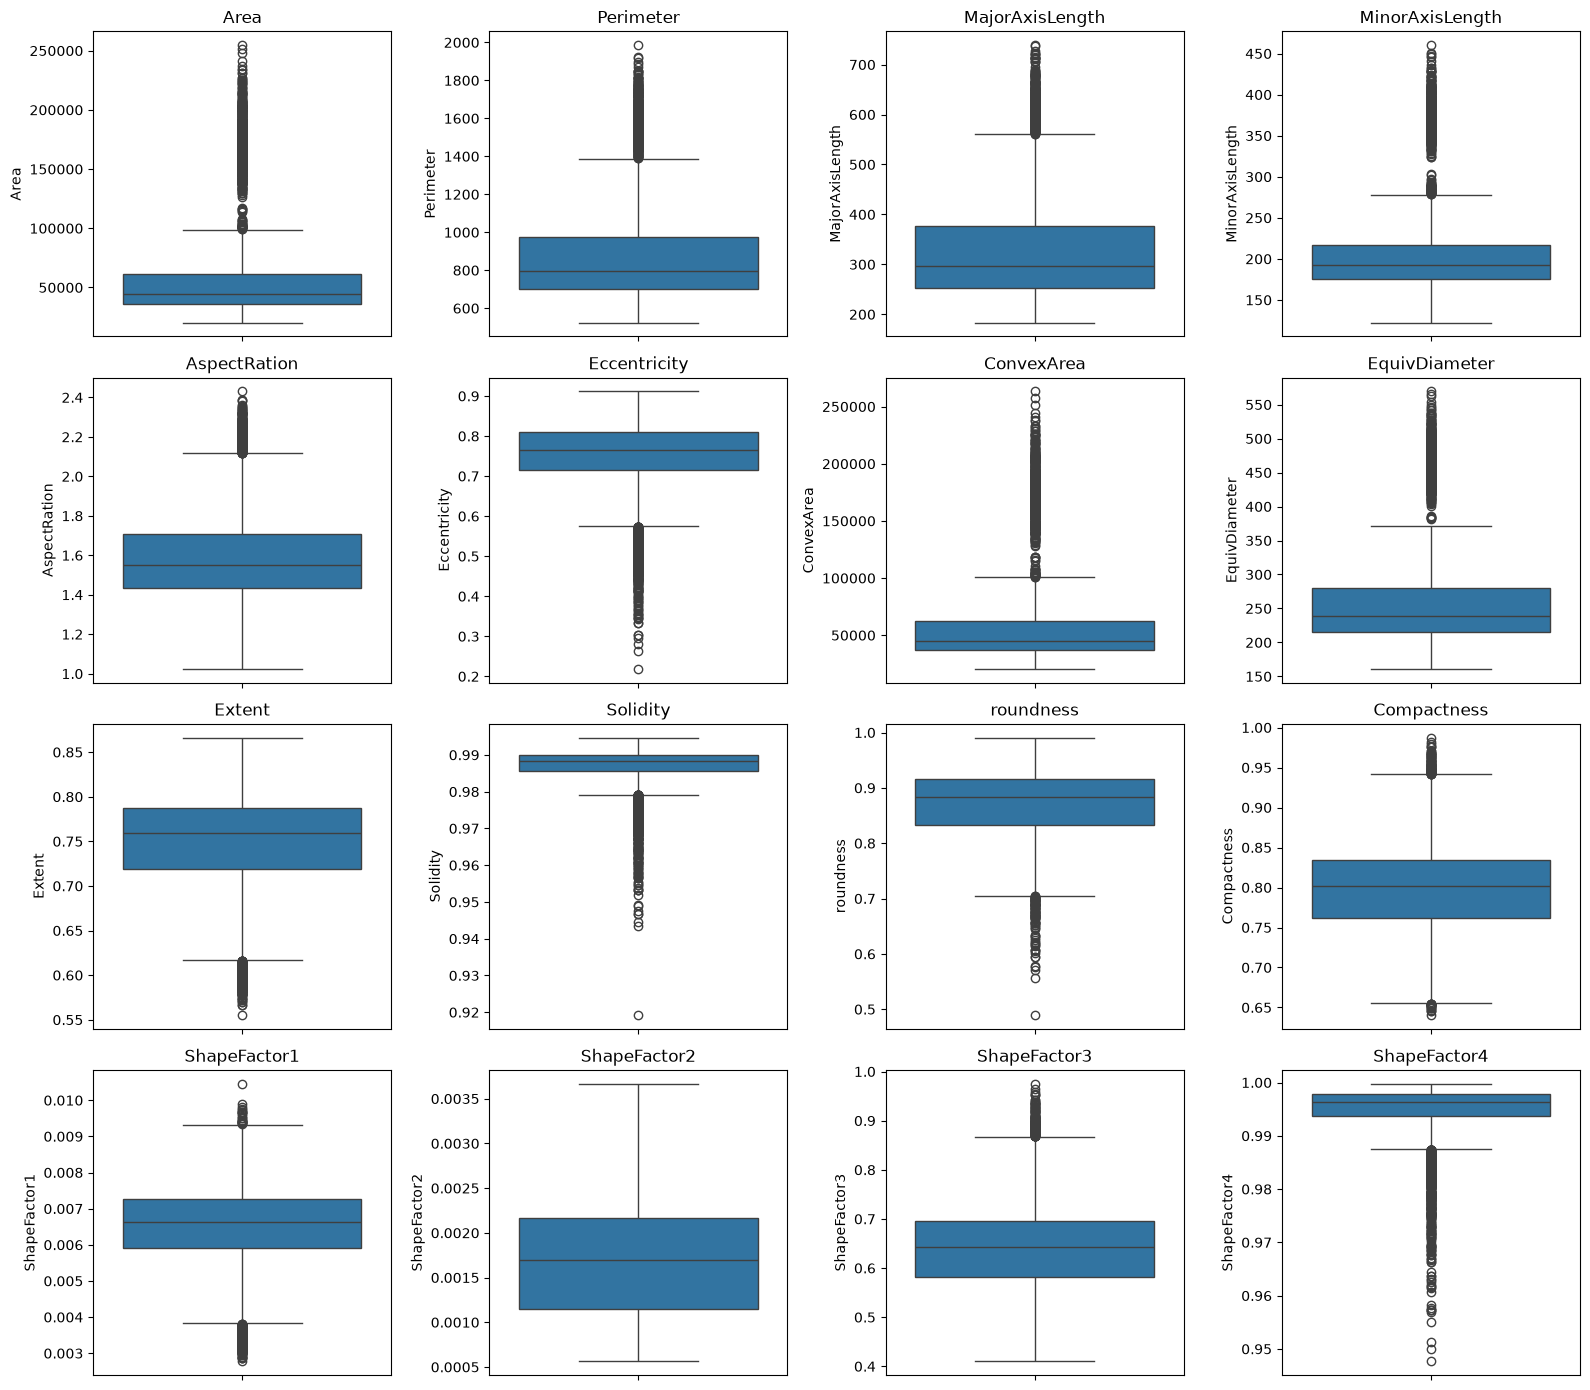

In [132]:
fig, axes = plt.subplots(4, 4, figsize=(16, 14))

for column, ax in zip(numeric_columns, axes.flatten()):
    sns.boxplot(y=df[column], ax=ax)
    ax.set_title(column)

plt.tight_layout()
plt.show()

# Boxplot Analysis:
The boxplots visually confirm the presence of potential outliers in several numerical attributes. Attributes such as Area, Perimeter, MajorAxisLength, MinorAxisLength, ConvexArea, and EquivDiameter show multiple observations beyond the whiskers, particularly toward higher values. This is consistent with the results obtained using the IQR method. The boxplots also show differences in the ranges and scales of the numerical attributes. These findings suggest that outliers and differences in feature scales should be considered during the preprocessing stage.

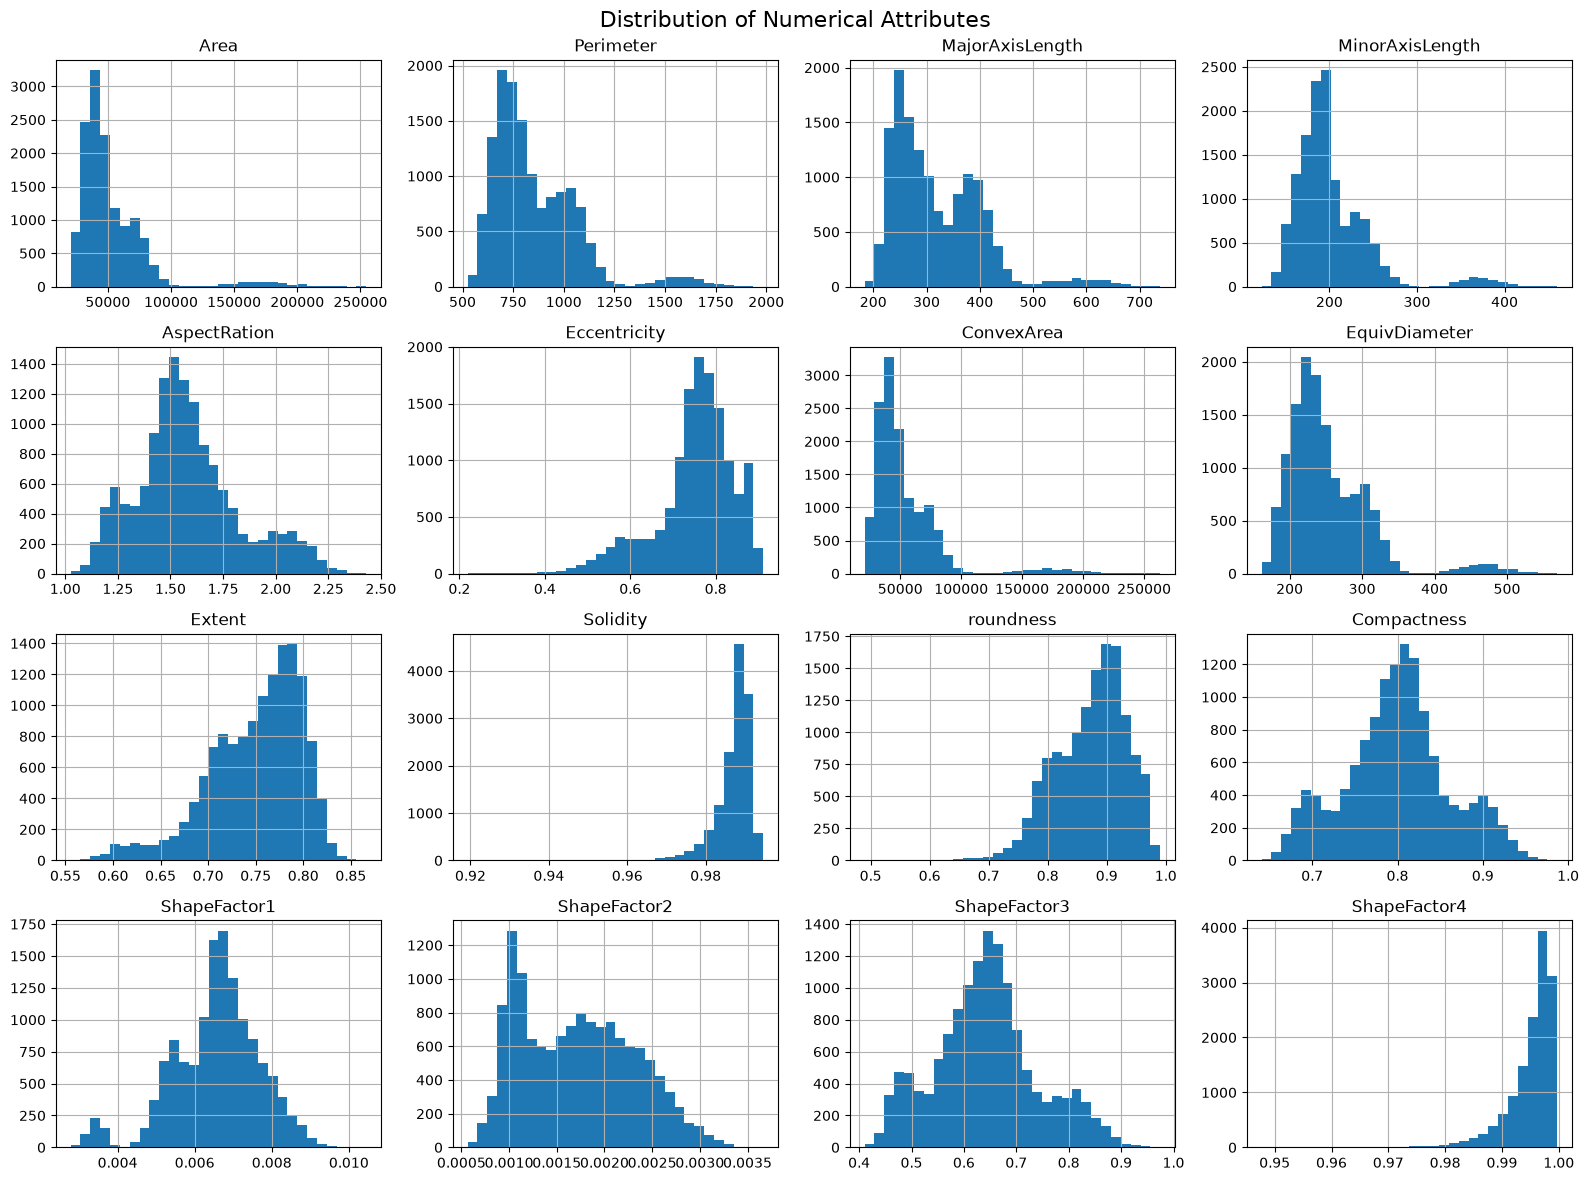

In [133]:
df[numeric_columns].hist(figsize=(16, 12), bins=30)

plt.suptitle("Distribution of Numerical Attributes", fontsize=16)
plt.tight_layout()
plt.show()

# Histogram Analysis:
The histograms show that the numerical attributes have different distribution patterns. Several attributes, such as Area and ConvexArea, are positively skewed, with most observations concentrated at lower values and a smaller number extending toward much higher values. Other attributes show different shapes and ranges, indicating that the numerical features are not distributed uniformly. These distributions, together with the previously detected outliers and differences in feature scales, suggest that appropriate preprocessing techniques should be considered before applying the data mining algorithms.

# Data Distribution and Relationships


This section analyzes missing values, class distribution, and relationships between selected numerical attributes. The results help identify whether preprocessing may be needed before applying data mining techniques.


## Check Missing Values


In [134]:
# Check for missing values in the entire dataset
missing_values = df.isna().sum()

# Display the results
print("Missing values in each column:")
print(missing_values)

# Calculate total missing values
print("\nTotal number of missing values:", missing_values.sum())

Missing values in each column:
,Area               0
,Perimeter          0
,MajorAxisLength    0
,MinorAxisLength    0
,AspectRation       0
,Eccentricity       0
,ConvexArea         0
,EquivDiameter      0
,Extent             0
,Solidity           0
,roundness          0
,Compactness        0
,ShapeFactor1       0
,ShapeFactor2       0
,ShapeFactor3       0
,ShapeFactor4       0
,Class              0
,dtype: int64
,
,Total number of missing values: 0


# Missing Values Analysis
The `isna()` function identifies missing values, and `sum()` counts the missing values in each column. If the total is zero, no missing-value treatment is required for the dataset.

## Class Distribution


In [135]:
# Count the observations in each class
class_counts = df['Class'].value_counts()

# Display the class counts
print("Number of observations in each class:")
print(class_counts)

Number of observations in each class:
,Class
,DERMASON    3546
,SIRA        2636
,SEKER       2027
,HOROZ       1928
,CALI        1630
,BARBUNYA    1322
,BOMBAY       522
,Name: count, dtype: int64


In [136]:
# Calculate the percentage of each class
class_percentage = df['Class'].value_counts(normalize=True) * 100

print("Percentage of observations in each class:")
print(class_percentage.round(2))

Percentage of observations in each class:
,Class
,DERMASON    26.05
,SIRA        19.37
,SEKER       14.89
,HOROZ       14.17
,CALI        11.98
,BARBUNYA     9.71
,BOMBAY       3.84
,Name: proportion, dtype: float64


# Class Distribution Analysis
The class distribution shows how many observations belong to each dry bean class. Comparing the class counts helps determine whether the classes are similarly represented or whether some classes have more observations than others.

# Class Balance Analysis

The class distribution is imbalanced because the number of observations varies significantly across classes. DERMASON represents 26.05% of the dataset, while BOMBAY represents only 3.84%. Therefore, some classes are more represented than others.

## Bar Plot


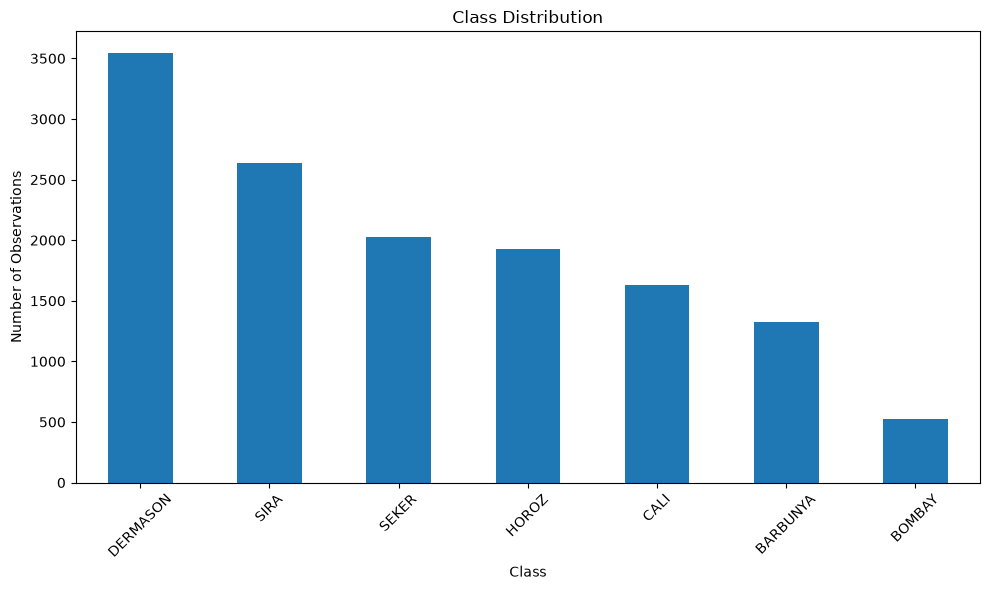

In [137]:
# Plot the number of observations in each class
plt.figure(figsize=(10, 6))
class_counts.plot(kind='bar')

plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Observations")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Bar Plot Analysis
The bar plot gives a visual comparison of the number of observations in each class. It makes differences in class sizes easier to identify.

## Relationship Between Area and Perimeter


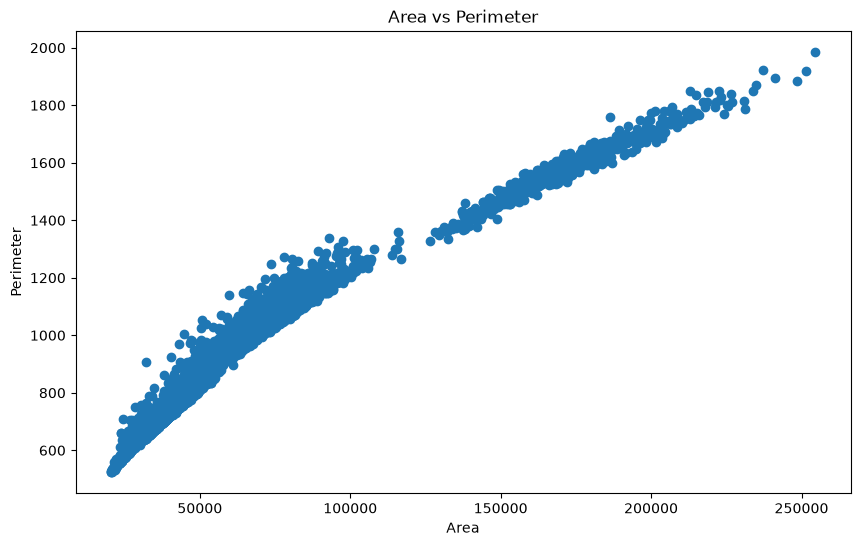

In [138]:
# Plot the relationship between Area and Perimeter
plt.figure(figsize=(10, 6))
plt.scatter(df['Area'], df['Perimeter'])

plt.title("Area vs Perimeter")
plt.xlabel("Area")
plt.ylabel("Perimeter")
plt.show()

# Scatter Plot Analysis
The scatter plot shows the relationship between Area and Perimeter. It helps us see whether the two numerical attributes change together and whether the observations form a clear pattern.

## Correlation Coefficient


In [139]:
# Calculate the correlation coefficient between Area and Perimeter
correlation = np.corrcoef(df['Area'], df['Perimeter'])[0, 1]

print("Correlation coefficient between Area and Perimeter:", correlation)

Correlation coefficient between Area and Perimeter: 0.9667221821788792


# Correlation Analysis
The correlation coefficient measures the strength and direction of the linear relationship between Area and Perimeter. A value close to 1 indicates a strong positive relationship, while a value close to 0 indicates a weak linear relationship.

# Data Distribution and Relationships Findings
The missing-value check determines whether missing-value treatment is required. The class distribution and bar plot show how the observations are distributed among the bean classes. The scatter plot and correlation coefficient provide information about the relationship between Area and Perimeter. These findings, together with the statistical summaries, boxplots, and histograms in the previous section, help identify suitable preprocessing techniques.

# [4] Data preprocessing

# Data Preprocessing
## 1. Noise Removal

The boxplot analysis and IQR method identified potential outliers in several numerical attributes, including Eccentricity, Solidity, ShapeFactor4, MinorAxisLength, Area, and ConvexArea. Therefore, the Interquartile Range (IQR) method was applied to remove observations containing values outside the lower and upper IQR boundaries.

In [140]:
import pandas as pd

df = pd.read_csv("Raw_dataset.csv")

print("Dataset shape:", df.shape)

Dataset shape: (13611, 17)


In [141]:
# Create a copy of the original dataset
Preprocessed_dataset = df.copy()

print("Original dataset shape:", Preprocessed_dataset.shape)

Original dataset shape: (13611, 17)


In [142]:
Q1 = Preprocessed_dataset[numeric_columns].quantile(0.25)
Q3 = Preprocessed_dataset[numeric_columns].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

In [143]:
numeric_columns = df.select_dtypes(include='number').columns

print(numeric_columns)

Index(['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength',
,       'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent',
,       'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2',
,       'ShapeFactor3', 'ShapeFactor4'],
,      dtype='str')


In [144]:
outlier_mask = (
    (Preprocessed_dataset[numeric_columns] < lower_bound) |
    (Preprocessed_dataset[numeric_columns] > upper_bound)
).any(axis=1)

In [145]:
Preprocessed_dataset = Preprocessed_dataset.loc[~outlier_mask].copy()

print("Preprocessed dataset shape:", Preprocessed_dataset.shape)
print("Number of rows removed:", len(df) - len(Preprocessed_dataset))

Preprocessed dataset shape: (10594, 17)
,Number of rows removed: 3017


In [146]:
Preprocessed_dataset.head()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
23,31637,656.711,229.719255,175.510446,1.308864,0.645191,32045,200.702465,0.761823,0.987268,0.921842,0.873686,0.007261,0.002610,0.763327,0.999091,SEKER
24,31675,657.431,236.752632,171.210559,1.382816,0.690678,32009,200.822963,0.740936,0.989565,0.920929,0.848240,0.007474,0.002387,0.719510,0.994950,SEKER
29,31811,642.092,223.984683,180.917123,1.238051,0.589565,32052,201.253629,0.773877,0.992481,0.969600,0.898515,0.007041,0.002831,0.807329,0.999515,SEKER
31,31823,662.532,222.872689,181.894696,1.225284,0.577858,32274,201.291585,0.774848,0.986026,0.911040,0.903168,0.007004,0.002875,0.815713,0.999481,SEKER
32,31837,656.404,224.912554,180.439422,1.246471,0.596968,32238,201.335857,0.785246,0.987561,0.928538,0.895174,0.007065,0.002798,0.801336,0.998843,SEKER


### Noise Removal Result

After applying the IQR-based noise removal technique, 3,017 observations containing potential outliers were removed. The dataset size decreased from 13,611 to 10,594 observations, while the original dataset remained unchanged. This resulted in a cleaner dataset with reduced influence from extreme values, supporting more reliable analysis and subsequent preprocessing steps.

## 2- Normalization - Min-Max Normalization

Min-Max Normalization was applied to scale the numerical attributes to a common range between 0 and 1. This helps reduce the effect of different feature scales and makes the attributes more comparable.

In [147]:
numeric_columns = Preprocessed_dataset.select_dtypes(include='number').columns

In [148]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

Preprocessed_dataset[numeric_columns] = scaler.fit_transform(
    Preprocessed_dataset[numeric_columns]
)

In [149]:
Preprocessed_dataset.head()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
23,0.144085,0.175629,0.153681,0.275552,0.097342,0.230771,0.143456,0.205000,0.581897,0.536943,0.796207,0.861504,0.561625,0.717059,0.844851,0.949636,SEKER
24,0.144573,0.176587,0.177118,0.245015,0.179717,0.378736,0.143001,0.205626,0.498222,0.689107,0.792828,0.746637,0.606862,0.627263,0.720235,0.612246,SEKER
29,0.146320,0.156174,0.134571,0.313948,0.018464,0.049827,0.143544,0.207864,0.630184,0.882200,0.972922,0.973586,0.514979,0.806139,0.969997,0.984209,SEKER
31,0.146474,0.183375,0.130866,0.320891,0.004242,0.011746,0.146348,0.208061,0.634072,0.454687,0.756235,0.994592,0.507007,0.823732,0.993841,0.981378,SEKER
32,0.146654,0.175220,0.137663,0.310556,0.027843,0.073909,0.145893,0.208291,0.675725,0.556372,0.820982,0.958504,0.519940,0.793002,0.952952,0.929411,SEKER


### Min-Max Normalization Result

After applying Min-Max Normalization, all numerical attributes were scaled to a range between 0 and 1. The number of observations remained unchanged at 10,594. This normalization makes the numerical attributes comparable despite their different original scales.

## 3. Correlation Analysis and Feature Selection
Correlation Analysis was applied to examine the relationships between numerical attributes. The correlation coefficient measures the strength and direction of the relationship between two numerical attributes. Attributes with a high absolute correlation may provide redundant information, so highly correlated attributes can be considered for feature selection.

In [150]:
correlation_matrix = Preprocessed_dataset[numeric_columns].corr()

upper = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

columns_to_remove = [
    column for column in upper.columns
    if any(upper[column].abs() > 0.75)
]

Preprocessed_dataset = Preprocessed_dataset.drop(columns=columns_to_remove)

print("Removed attributes:")
print(columns_to_remove)

print("\nPreprocessed dataset shape:")
print(Preprocessed_dataset.shape)
Preprocessed_dataset.to_csv('Preprocessed_dataset.csv', index=False)

Removed attributes:
,['Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3']
,
,Preprocessed dataset shape:
,(10594, 6)


### Correlation Analysis Result

Correlation analysis identified several highly correlated numerical attributes. Attributes with an absolute correlation greater than 0.75 were removed to reduce redundancy. After feature selection, the preprocessed dataset contained 10,594 observations and 6 attributes.

# [5] Data Mining Technique

### Classification

Decision Tree classification was applied to classify dry beans into their corresponding classes based on the selected features. Two attribute selection measures were evaluated: **Information Gain (Entropy)** and **Gini Index**. Each criterion was tested using three training/testing partitions: **90/10, 80/20, and 70/30**.

The models were implemented using `DecisionTreeClassifier` from the `sklearn.tree` package. Their performance was evaluated using accuracy and confusion matrices.

### Clustering

K-Means clustering was applied to group dry beans with similar characteristics without using the class label. The numerical features were standardized using `StandardScaler`, and K-Means was implemented using `KMeans` from the `sklearn.cluster` package.

Three values of K (**2, 3, and 4**) were evaluated using the **Silhouette Score** and **WCSS**. Cluster visualizations and evaluation measures were used to determine and interpret the optimal number of clusters.

# [6] Evaluation and Comparison

In [1]:
import pandas as pd

url = "Preprocessed_dataset.csv"

df = pd.read_csv(url)

df.head()

,Area,AspectRation,Extent,Solidity,ShapeFactor4,Class
0,0.144085,0.097342,0.581897,0.536943,0.949636,SEKER
1,0.144573,0.179717,0.498222,0.689107,0.612246,SEKER
2,0.146320,0.018464,0.630184,0.882200,0.984209,SEKER
3,0.146474,0.004242,0.634072,0.454687,0.981378,SEKER
4,0.146654,0.027843,0.675725,0.556372,0.929411,SEKER


## Feature Selection

In [2]:
X = df.drop("Class", axis=1)
y = df["Class"]

print("Features:")
print(X.columns)

print("\nTarget:")
print(y.name)

Features:
,Index(['Area', 'AspectRation', 'Extent', 'Solidity', 'ShapeFactor4'], dtype='object')
,
,Target:
,Class


## Data Splitting - 90% Training / 10% Testing

In [3]:
from sklearn.model_selection import train_test_split

X_train_90, X_test_10, y_train_90, y_test_10 = train_test_split(
    X,
    y,
    test_size=0.10,
    random_state=42
)

print("Training size:", len(X_train_90))
print("Testing size:", len(X_test_10))

Training size: 9534
,Testing size: 1060


## Decision Tree using Information Gain (Entropy) - 90/10 Split

In [4]:
from sklearn.tree import DecisionTreeClassifier

entropy_model_90 = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42
)

entropy_model_90.fit(X_train_90, y_train_90)

y_pred_90 = entropy_model_90.predict(X_test_10)

### Accuracy - 90/10 Split

In [5]:
from sklearn.metrics import accuracy_score

accuracy_90 = accuracy_score(y_test_10, y_pred_90)

print("Accuracy for 90/10 split:", accuracy_90)

Accuracy for 90/10 split: 0.8735849056603774


### Confusion Matrix - 90/10 Split

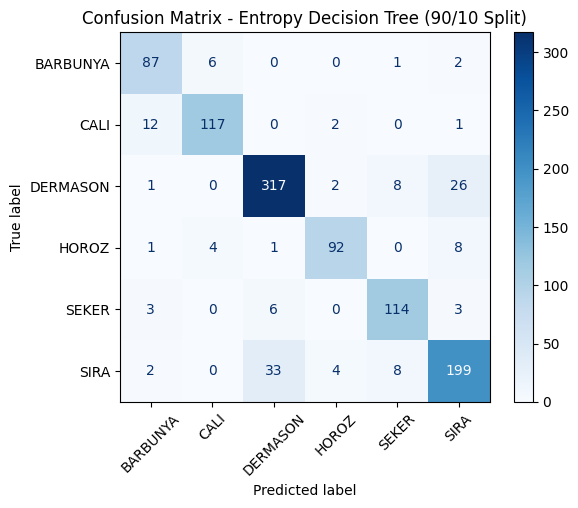

In [6]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_90 = confusion_matrix(y_test_10, y_pred_90)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_90,
    display_labels=entropy_model_90.classes_
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix - Entropy Decision Tree (90/10 Split)")
plt.xticks(rotation=45)
plt.show()

## Data Splitting - 80% Training / 20% Testing

In [7]:
X_train_80, X_test_20, y_train_80, y_test_20 = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training size:", len(X_train_80))
print("Testing size:", len(X_test_20))

Training size: 8475
,Testing size: 2119


## Decision Tree using Information Gain (Entropy) - 80/20 Split

In [8]:
entropy_model_80 = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42
)

entropy_model_80.fit(X_train_80, y_train_80)

y_pred_80 = entropy_model_80.predict(X_test_20)

### Accuracy - 80/20 Split

In [9]:
accuracy_80 = accuracy_score(y_test_20, y_pred_80)

print("Accuracy for 80/20 split:", accuracy_80)

Accuracy for 80/20 split: 0.8617272298253893


### Confusion Matrix - 80/20 Split

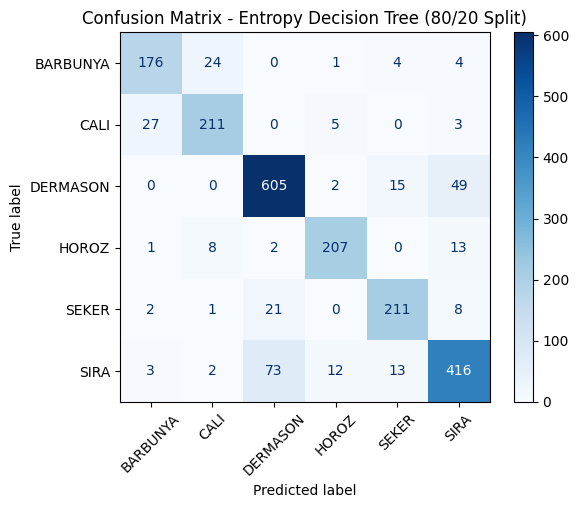

In [10]:
cm_80 = confusion_matrix(y_test_20, y_pred_80)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_80,
    display_labels=entropy_model_80.classes_
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix - Entropy Decision Tree (80/20 Split)")
plt.xticks(rotation=45)
plt.show()

## Data Splitting - 70% Training / 30% Testing

In [11]:
X_train_70, X_test_30, y_train_70, y_test_30 = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)

print("Training size:", len(X_train_70))
print("Testing size:", len(X_test_30))

Training size: 7415
,Testing size: 3179


## Decision Tree using Information Gain (Entropy) - 70/30 Split

In [12]:
entropy_model_70 = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42
)

entropy_model_70.fit(X_train_70, y_train_70)

y_pred_70 = entropy_model_70.predict(X_test_30)

### Accuracy - 70/30 Split

In [13]:
accuracy_70 = accuracy_score(y_test_30, y_pred_70)

print("Accuracy for 70/30 split:", accuracy_70)

Accuracy for 70/30 split: 0.8688266750550487


### Confusion Matrix - 70/30 Split

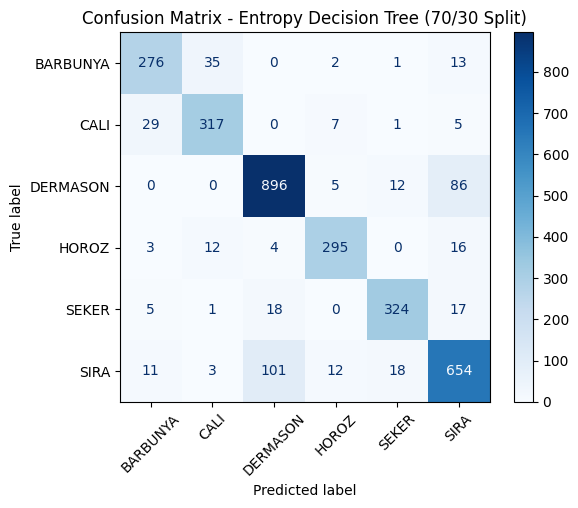

In [14]:
cm_70 = confusion_matrix(y_test_30, y_pred_70)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_70,
    display_labels=entropy_model_70.classes_
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix - Entropy Decision Tree (70/30 Split)")
plt.xticks(rotation=45)
plt.show()

### Accuracy Comparison for Different Data Splits
The following table compares the accuracy of the Entropy-based Decision Tree using three different training and testing partitions.

In [15]:
results_entropy = pd.DataFrame({
    "Training Size": ["90%", "80%", "70%"],
    "Testing Size": ["10%", "20%", "30%"],
    "Accuracy": [accuracy_90, accuracy_80, accuracy_70]
})

results_entropy

,Training Size,Testing Size,Accuracy
0,90%,10%,0.873585
1,80%,20%,0.861727
2,70%,30%,0.868827


### Results Discussion

The Entropy-based Decision Tree was evaluated using three different training and testing partitions. The 90/10 split achieved the highest accuracy of approximately **87.36%**, followed by the 70/30 split with approximately **86.88%**, while the 80/20 split achieved approximately **86.17%**.

Therefore, the **90% training and 10% testing split achieved the best performance** among the three partitions. The results also show that the accuracy remained relatively consistent across all three partitions.

### Entropy Decision Tree Visualization - Best Split (90/10)

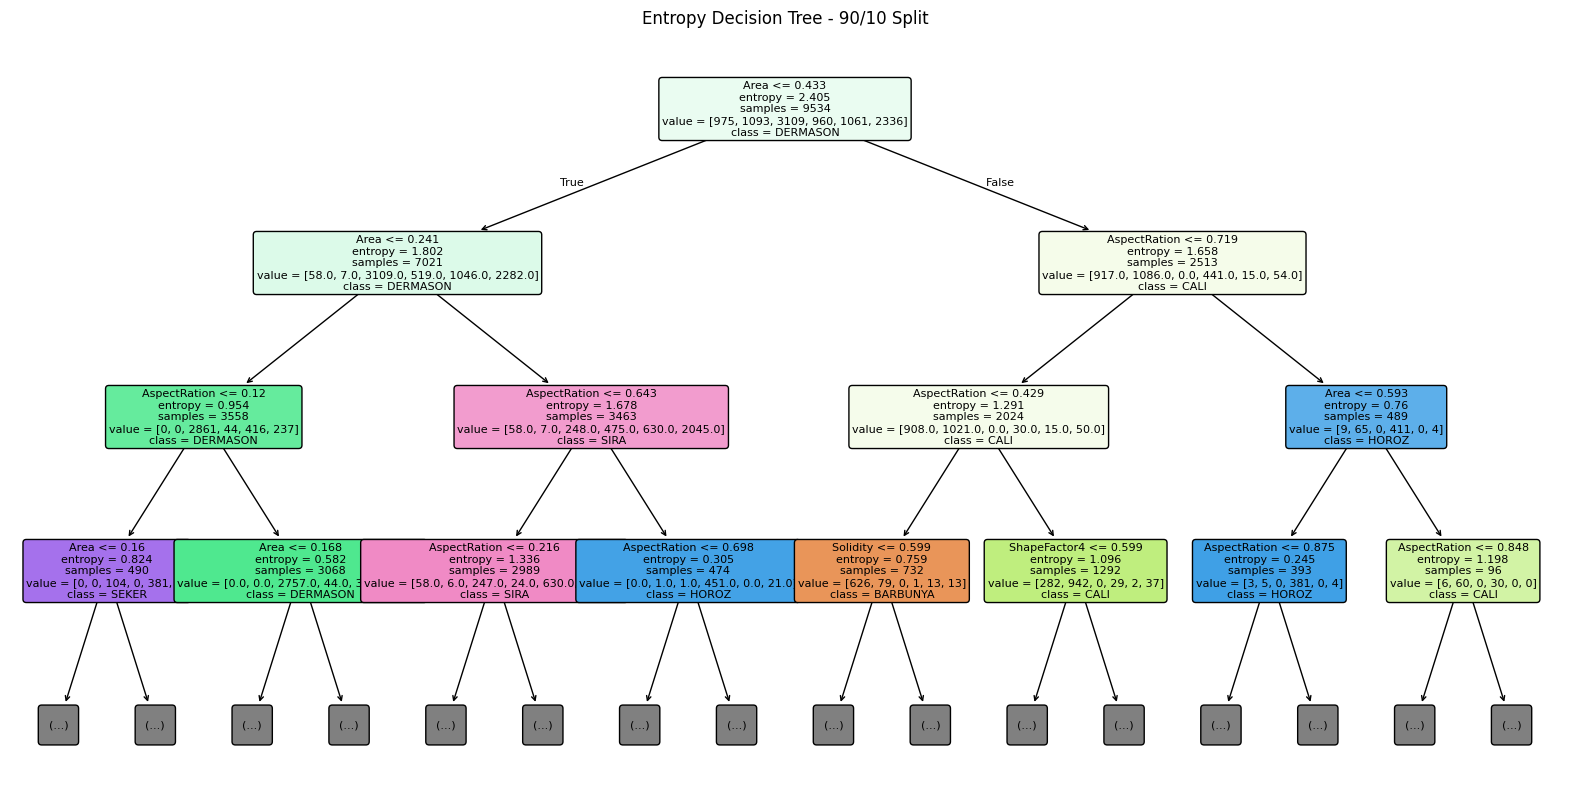

In [16]:
from sklearn import tree
import matplotlib.pyplot as plt

plt.figure(figsize=(20, 10))

tree.plot_tree(
    entropy_model_90,
    feature_names=X.columns,
    class_names=entropy_model_90.classes_,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title("Entropy Decision Tree - 90/10 Split")
plt.show()

The Entropy-based Decision Tree classifies the dry beans by progressively splitting the data using the most informative features. The tree starts with **Area** as the root node, then uses other features such as **AspectRation, Solidity, and ShapeFactor4** in the following nodes. At each node, a condition is evaluated and the data moves to the left or right branch depending on the result. This process continues until the model reaches a predicted bean class. The tree shows that size and shape-related features play an important role in distinguishing between the dry bean classes.

## Decision Tree using Gini Index

The Decision Tree is applied using the Gini index. The same feature set, target column, data partitions, and `random_state=42` used in the existing Entropy experiments are retained so the results can be compared fairly.

### Gini Index - 90/10 Split

Accuracy for Gini 90/10 split: 0.8650943396226415


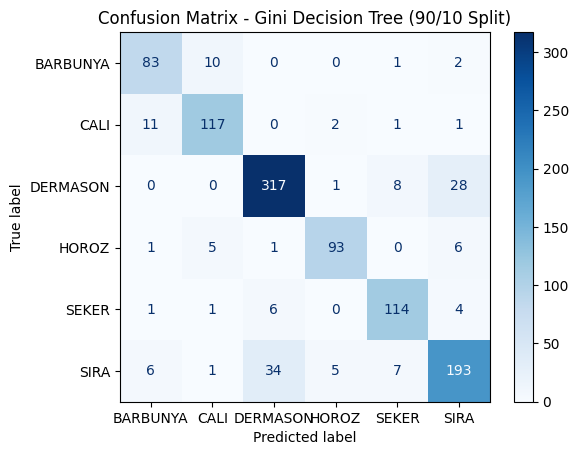

In [17]:
gini_model_90 = DecisionTreeClassifier(criterion="gini", random_state=42)
gini_model_90.fit(X_train_90, y_train_90)
y_pred_gini_90 = gini_model_90.predict(X_test_10)

accuracy_gini_90 = accuracy_score(y_test_10, y_pred_gini_90)
print("Accuracy for Gini 90/10 split:", accuracy_gini_90)

cm_gini_90 = confusion_matrix(y_test_10, y_pred_gini_90)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_gini_90, display_labels=gini_model_90.classes_)
disp.plot(cmap="Blues")
plt.title("Confusion Matrix - Gini Decision Tree (90/10 Split)")
plt.show()

### Gini Index - 80/20 Split

Accuracy for Gini 80/20 split: 0.8706937234544596


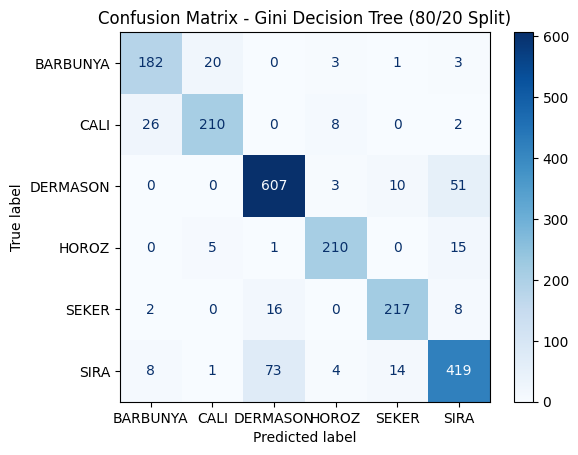

In [18]:
gini_model_80 = DecisionTreeClassifier(criterion="gini", random_state=42)
gini_model_80.fit(X_train_80, y_train_80)
y_pred_gini_80 = gini_model_80.predict(X_test_20)

accuracy_gini_80 = accuracy_score(y_test_20, y_pred_gini_80)
print("Accuracy for Gini 80/20 split:", accuracy_gini_80)

cm_gini_80 = confusion_matrix(y_test_20, y_pred_gini_80)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_gini_80, display_labels=gini_model_80.classes_)
disp.plot(cmap="Blues")
plt.title("Confusion Matrix - Gini Decision Tree (80/20 Split)")
plt.show()

### Gini Index - 70/30 Split

Accuracy for Gini 70/30 split: 0.8647373387857817


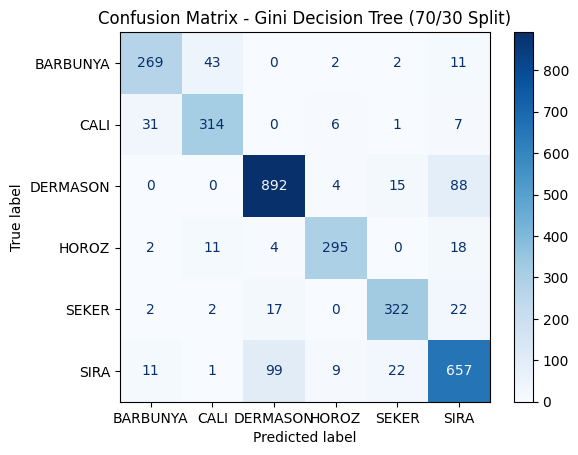

In [19]:
gini_model_70 = DecisionTreeClassifier(criterion="gini", random_state=42)
gini_model_70.fit(X_train_70, y_train_70)
y_pred_gini_70 = gini_model_70.predict(X_test_30)

accuracy_gini_70 = accuracy_score(y_test_30, y_pred_gini_70)
print("Accuracy for Gini 70/30 split:", accuracy_gini_70)

cm_gini_70 = confusion_matrix(y_test_30, y_pred_gini_70)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_gini_70, display_labels=gini_model_70.classes_)
disp.plot(cmap="Blues")
plt.title("Confusion Matrix - Gini Decision Tree (70/30 Split)")
plt.show()

### Accuracy Comparison for Gini Index

In [20]:
results_gini = pd.DataFrame({
    "Training Size": ["90%", "80%", "70%"],
    "Testing Size": ["10%", "20%", "30%"],
    "Accuracy": [accuracy_gini_90, accuracy_gini_80, accuracy_gini_70]
})

results_gini

,Training Size,Testing Size,Accuracy
0,90%,10%,0.865094
1,80%,20%,0.870694
2,70%,30%,0.864737


### Gini Decision Tree Visualization - 90/10 Split

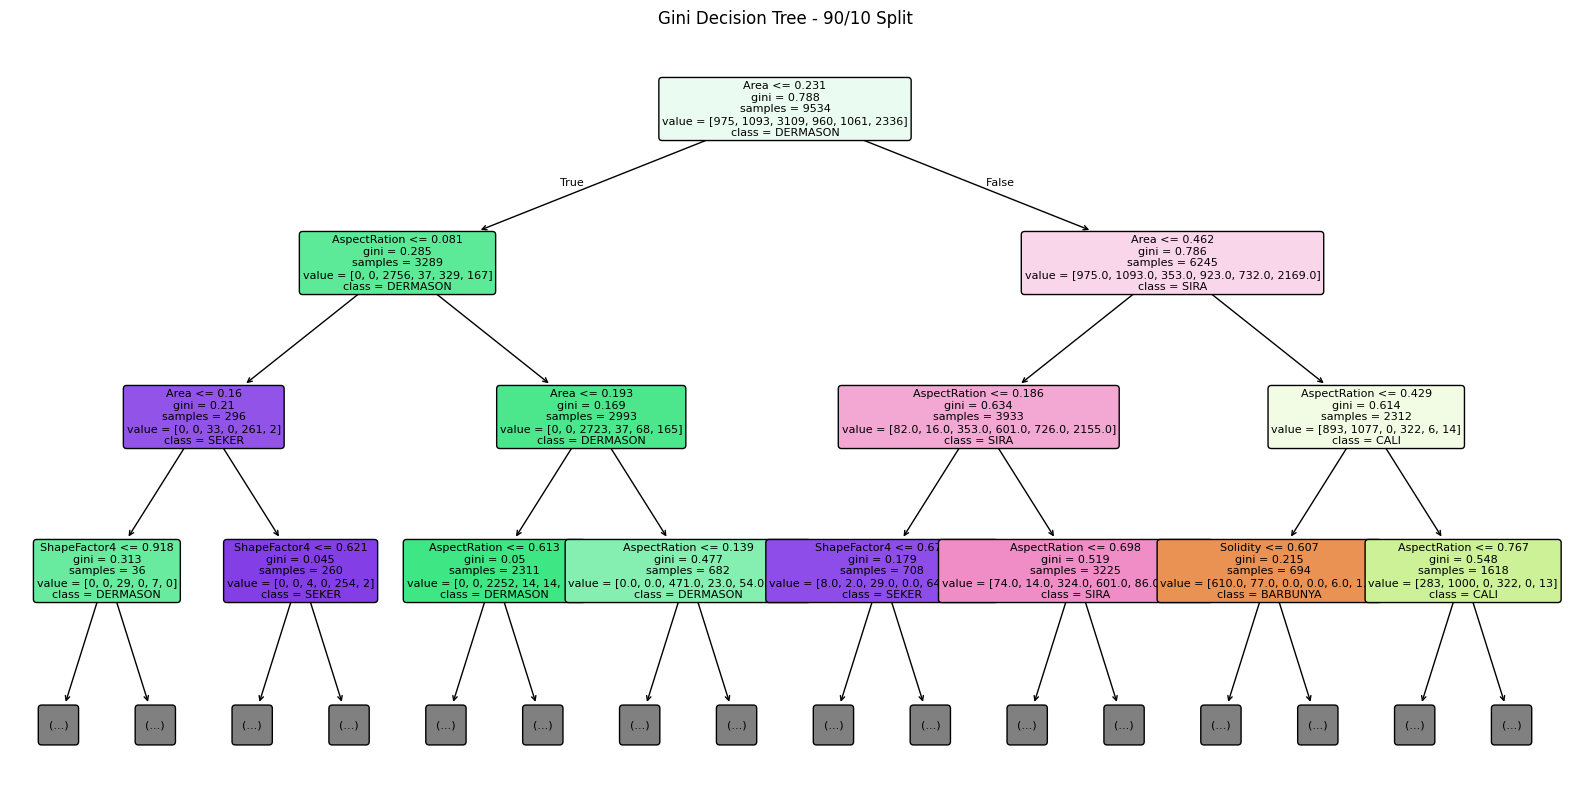

In [21]:
plt.figure(figsize=(20, 10))
tree.plot_tree(
    gini_model_90,
    feature_names=X.columns,
    class_names=[str(c) for c in gini_model_90.classes_],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)
plt.title("Gini Decision Tree - 90/10 Split")
plt.show()

## Final Comparison: Gini Index and Entropy

The following table compares the two attribute-selection measures on the same three data partitions. The accuracy values are taken from the model results above; no values are entered manually.

The table compares the accuracy results for the three data partitions.

| Data Split | Entropy Accuracy | Gini Accuracy | Higher Accuracy |
|---|---:|---:|---|
| 90/10 | 87.36% | 86.51% | Entropy |
| 80/20 | 86.17% | 87.07% | Gini |
| 70/30 | 86.88% | 86.47% | Entropy |

Entropy achieved an average accuracy of 86.80%, while Gini achieved 86.68%. Therefore, Entropy performed slightly better overall across the three data partitions.

### Interpretation

The results show that Entropy achieved a higher accuracy than Gini for the 90/10 and 70/30 data splits, while Gini performed better for the 80/20 split.

The average accuracy of Entropy was 86.80%, compared with 86.68% for Gini. Therefore, Entropy achieved a slightly higher average accuracy across the three data splits.

These results indicate that Entropy performed slightly better overall on this dataset, although Gini achieved better accuracy for the 80/20 split.

# K-Means Clustering

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt


X = df.drop(columns=["Class", "Cluster"], errors="ignore")


scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Features shape:", X_scaled.shape)


Features shape: (10594, 5)


/lib/python3.14/site-packages/threadpoolctl.py:1135: RuntimeWarning: JsProxy.as_object_map() is deprecated. Use as_py_json() instead.
  for filepath in LDSO.loadedLibsByName.as_object_map():


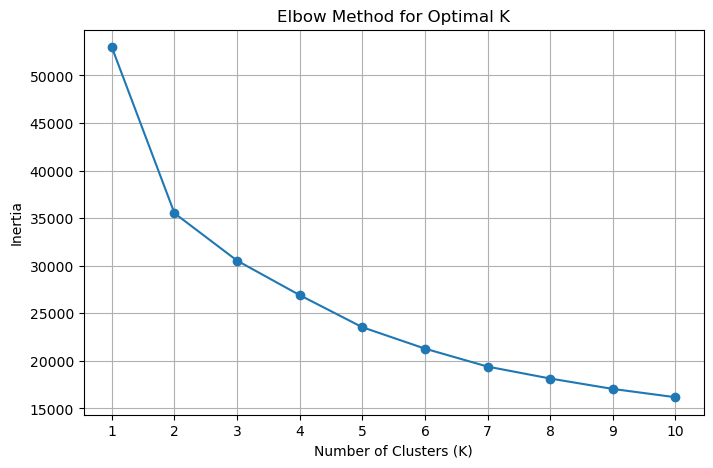

In [3]:
inertia_values = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia_values.append(kmeans.inertia_)


plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia_values, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal K')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

The Elbow Method was used to examine different numbers of clusters. The plot shows a sharp decrease in inertia when increasing K from 1 to 2, followed by a more gradual decrease. Therefore, K values of 2, 3, and 4 were selected for further comparison.

In [4]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

cluster_labels = kmeans.fit_predict(X_scaled)

df["Cluster"] = cluster_labels

print("Number of samples in each cluster:")
print(df["Cluster"].value_counts().sort_index())

Number of samples in each cluster:
Cluster
0    5881
1    2533
2    2180
Name: count, dtype: int64


In [5]:
silhouette_avg = silhouette_score(X_scaled, cluster_labels)

print("Silhouette Score:", silhouette_avg)

Silhouette Score: 0.3030520901204771


In [6]:
cluster_analysis = df.groupby("Cluster")[
    ["Area", "AspectRation", "Extent", "Solidity", "ShapeFactor4"]
].mean().round(4)

print("Average feature values for each cluster:")
display(cluster_analysis)

Average feature values for each cluster:


,Area,AspectRation,Extent,Solidity,ShapeFactor4
Cluster,,,,,
0,0.2178,0.2608,0.5883,0.6667,0.8067
1,0.5919,0.5397,0.6412,0.4629,0.4968
2,0.3870,0.5560,0.3031,0.4917,0.5946


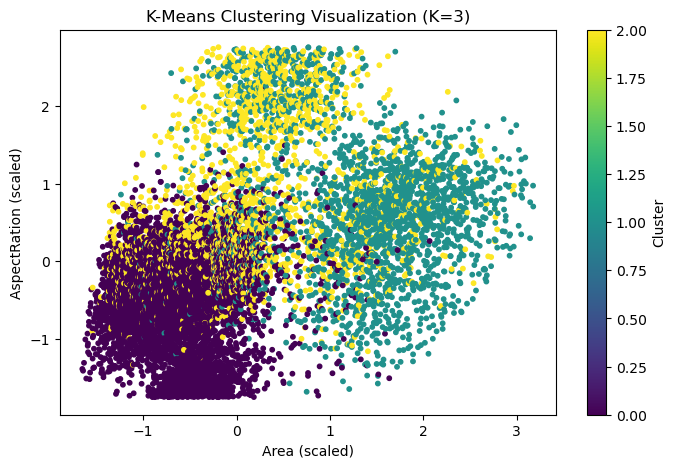

In [7]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=cluster_labels,
    cmap="viridis",
    s=10
)

plt.xlabel("Area (scaled)")
plt.ylabel("AspectRation (scaled)")
plt.title("K-Means Clustering Visualization (K=3)")
plt.colorbar(label="Cluster")
plt.show()

## K-Means Clustering Results and Discussion

The K-Means algorithm was applied to the preprocessed Dry Bean dataset using five numerical features: Area, AspectRation, Extent, Solidity, and ShapeFactor4. The features were standardized before clustering to ensure that they contributed on comparable scales.

The Elbow Method was used to examine different numbers of clusters, and three clusters (K = 3) were selected for the initial analysis. The resulting cluster sizes are reported in the output above.

The Silhouette Score was used to evaluate cluster separation. The score indicates how well the observations fit within their assigned clusters compared with other clusters. The cluster analysis also showed differences in the average feature values among the three groups.

The scatter plot of Area and AspectRation provides a visual representation of the clusters, although some observations overlap.

Overall, K-Means identified groups with different feature characteristics in the dataset. However, the clustering results do not directly represent the original bean classes, since the Class column was excluded from the clustering process.


In [8]:
k_values = [2, 3, 4]
comparison_results = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    comparison_results.append({
        "K": k,
        "Silhouette Score": round(score, 4),
        "Total Within-Cluster Sum of Squares (Inertia)": round(model.inertia_, 2)
    })

comparison_df = pd.DataFrame(comparison_results)
display(comparison_df)

,K,Silhouette Score,Total Within-Cluster Sum of Squares (Inertia)
0,2,0.3370,35522.56
1,3,0.3031,30538.48
2,4,0.2938,26911.59


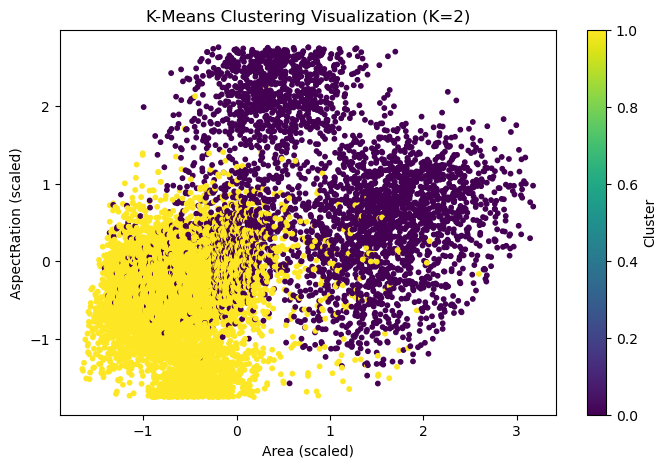

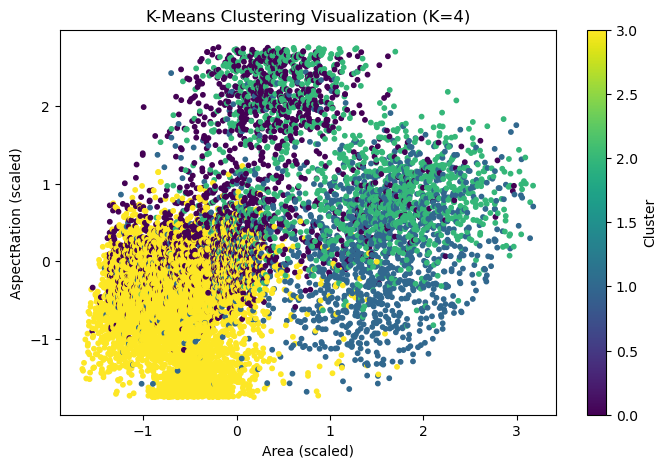

In [9]:
for k in [2, 4]:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)

    plt.figure(figsize=(8, 5))
    plt.scatter(
        X_scaled[:, 0],
        X_scaled[:, 1],
        c=labels,
        cmap="viridis",
        s=10
    )

    plt.xlabel("Area (scaled)")
    plt.ylabel("AspectRation (scaled)")
    plt.title(f"K-Means Clustering Visualization (K={k})")
    plt.colorbar(label="Cluster")
    plt.show()

## Comparison and Interpretation of K-Means Results

Three values of K (2, 3, and 4) were evaluated using the Silhouette Score and the total within-cluster sum of squares (Inertia).

The Silhouette Scores and Inertia values are summarized in the comparison table above. The highest Silhouette Score among the tested values indicates the strongest cluster separation according to this metric.

The Inertia values generally decrease as the number of clusters increases. This decrease is expected, so Inertia should be considered alongside the Silhouette Score rather than used alone.

The visualizations show how the cluster distributions change for different values of K. Some observations overlap, indicating that the clusters are not completely separated.

Based on the comparison results, **K = 2 achieved the highest Silhouette Score** among the three tested values. However, the final optimal K was determined using the majority rule by considering the Silhouette Score, Elbow Method, and Calinski–Harabasz Index together.


# Clustering — Visualization & Evaluation

In this section the K-Means models built above (K = 2, 3 and 4) are **visualized, evaluated and compared**. For each K we show:

1. A picture of the coloured clusters.
2. The average Silhouette width and the total within-cluster sum of squares (WCSS).
3. An interpretation of what each cluster contains.

Finally, the best K is chosen with the **majority rule**, the clusters are described using the dataset's columns, and the results are compared with the selected research paper.

## 1. Fitting the final K-Means models (K = 2, 3, 4)

The same standardized features (`X_scaled`), `random_state=42` and `n_init=10` used in the K-Means section are reused, so the results match the comparison table above.

In [22]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, calinski_harabasz_score
from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt

k_values = [2, 3, 4]
kmeans_models = {}
kmeans_labels = {}

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_labels[k] = model.fit_predict(X_scaled)
    kmeans_models[k] = model
    print(f"K={k}: cluster sizes =", np.bincount(kmeans_labels[k]))

K=2: cluster sizes = [4021 6573]
K=3: cluster sizes = [5881 2533 2180]
K=4: cluster sizes = [1867 1541 1556 5630]


## 2. Visualization of the clusters for each K

The data has 5 features, so it cannot be drawn directly. **PCA** (Principal Component Analysis) is used only for plotting: it projects the 5 standardized features onto 2 axes that keep most of the variation. The black **X** marks are the cluster centroids.

Variance explained by the 2 PCA components: 65.48 %


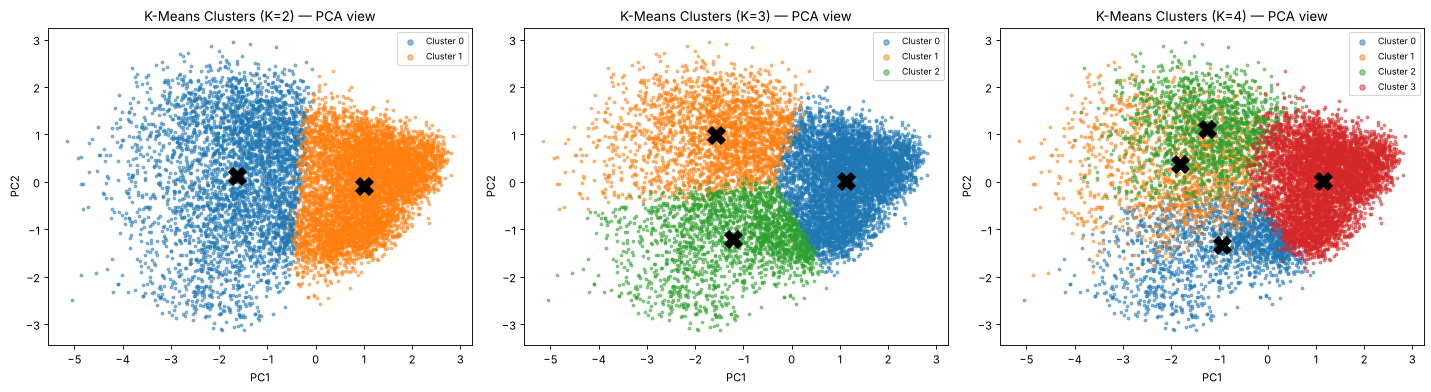

In [23]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
print("Variance explained by the 2 PCA components:", round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, k in zip(axes, k_values):
    labels = kmeans_labels[k]
    for c in range(k):
        ax.scatter(X_pca[labels == c, 0], X_pca[labels == c, 1],
                   s=6, alpha=0.5, color=colors[c], label=f"Cluster {c}")
    centers = pca.transform(kmeans_models[k].cluster_centers_)
    ax.scatter(centers[:, 0], centers[:, 1], marker="X", s=250, color="black")
    ax.set_title(f"K-Means Clusters (K={k}) — PCA view")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.legend(markerscale=2, fontsize=8)
plt.tight_layout()
plt.show()

The same clusters are also shown on two **original columns** (Area and AspectRation, preprocessed values) so the groups can be read in terms of bean size and shape.

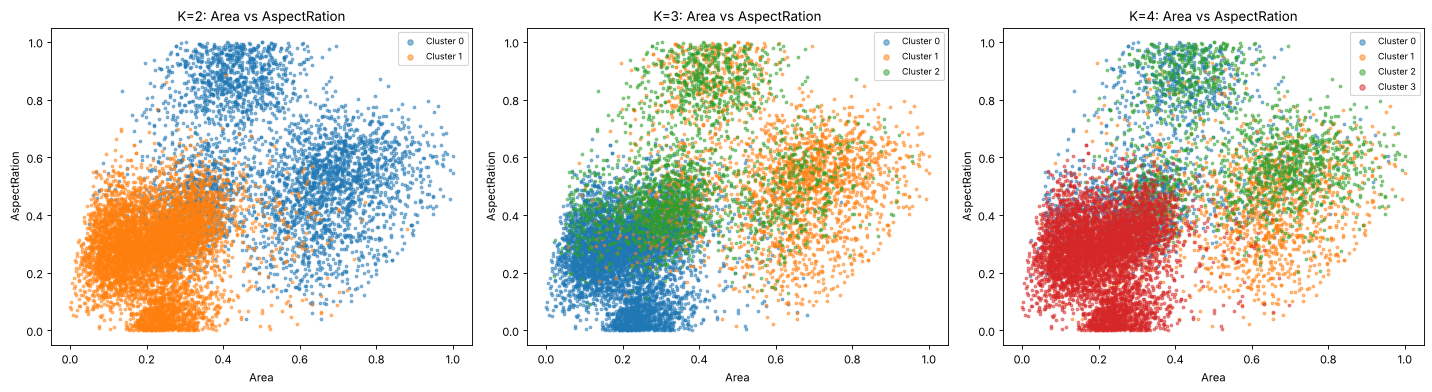

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, k in zip(axes, k_values):
    labels = kmeans_labels[k]
    for c in range(k):
        ax.scatter(df.loc[labels == c, "Area"], df.loc[labels == c, "AspectRation"],
                   s=6, alpha=0.5, color=colors[c], label=f"Cluster {c}")
    ax.set_title(f"K={k}: Area vs AspectRation")
    ax.set_xlabel("Area")
    ax.set_ylabel("AspectRation")
    ax.legend(markerscale=2, fontsize=8)
plt.tight_layout()
plt.show()

## 3. Silhouette plots for each K

The silhouette value of each point measures how close it is to its own cluster compared with the nearest other cluster (from −1 to 1). The red dashed line is the **average silhouette width**. Wide bars that pass the red line and few negative values mean good clusters.

K=2: average silhouette = 0.3370, negative points = 8.4%
K=3: average silhouette = 0.3031, negative points = 7.4%
K=4: average silhouette = 0.2938, negative points = 5.2%


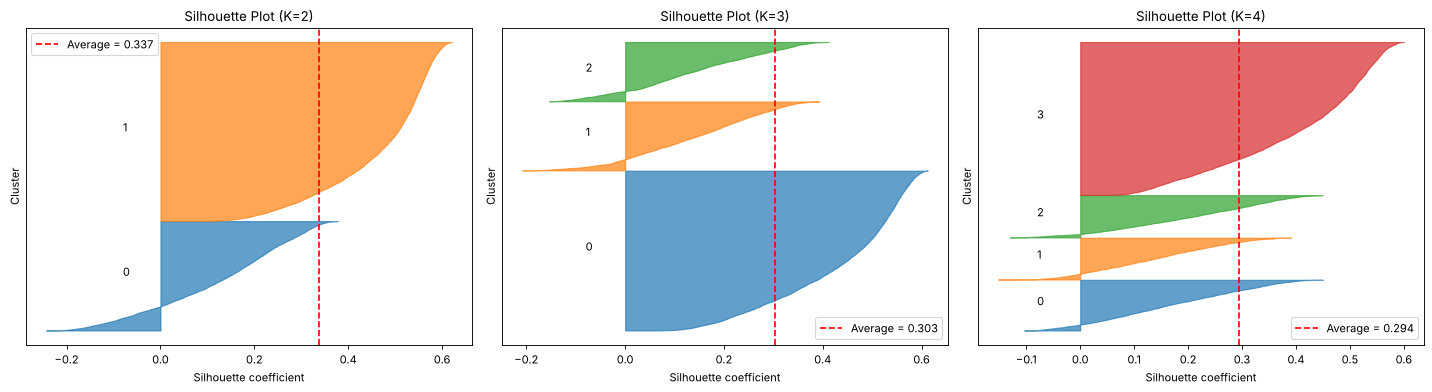

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, k in zip(axes, k_values):
    labels = kmeans_labels[k]
    sil_values = silhouette_samples(X_scaled, labels)
    sil_avg = silhouette_score(X_scaled, labels)
    y_lower = 10
    for c in range(k):
        vals = np.sort(sil_values[labels == c])
        y_upper = y_lower + len(vals)
        ax.fill_betweenx(np.arange(y_lower, y_upper), 0, vals, color=colors[c], alpha=0.7)
        ax.text(-0.08, y_lower + len(vals) / 2, str(c))
        y_lower = y_upper + 10
    ax.axvline(sil_avg, color="red", linestyle="--", label=f"Average = {sil_avg:.3f}")
    ax.set_title(f"Silhouette Plot (K={k})")
    ax.set_xlabel("Silhouette coefficient")
    ax.set_ylabel("Cluster")
    ax.set_yticks([])
    ax.legend()
    print(f"K={k}: average silhouette = {sil_avg:.4f}, negative points = {(sil_values < 0).mean() * 100:.1f}%")
plt.tight_layout()
plt.show()

## 4. Elbow method and Silhouette across K

WCSS (inertia) and the average silhouette width are calculated for K = 1 to 10 to see where the tested values (2, 3, 4) fall. As in the course slides, the elbow point is located automatically with `KneeLocator` from the `kneed` package.

In [26]:
%pip install kneed

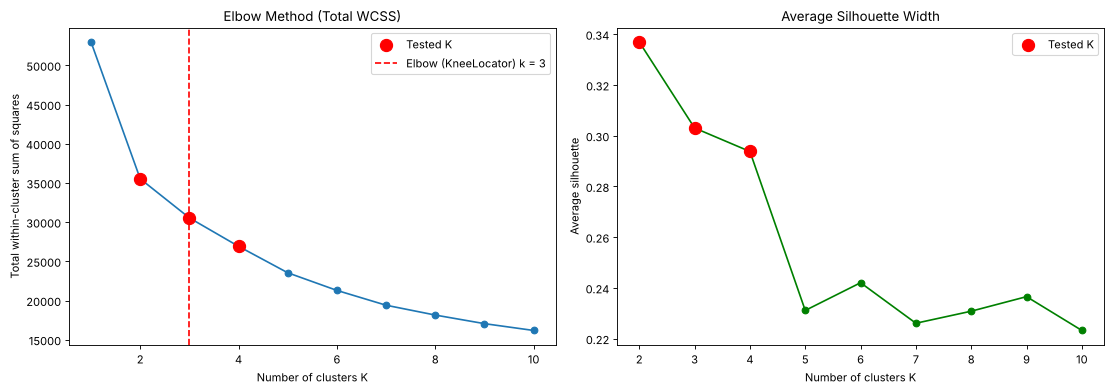

WCSS drop when K increases:
  K=1 -> K=2: 17447.4
  K=2 -> K=3: 4984.1
  K=3 -> K=4: 3626.9
  K=4 -> K=5: 3371.6

Elbow point found by KneeLocator: K = 3


In [27]:
from kneed import KneeLocator

k_range = range(1, 11)
wcss_all, sil_all = [], []
for k in k_range:
    m = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled)
    wcss_all.append(m.inertia_)
    sil_all.append(silhouette_score(X_scaled, m.labels_) if k > 1 else np.nan)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(k_range, wcss_all, marker="o")
axes[0].scatter(k_values, [wcss_all[k - 1] for k in k_values], s=120, color="red", zorder=3, label="Tested K")
axes[0].set_title("Elbow Method (Total WCSS)")
axes[0].set_xlabel("Number of clusters K")
axes[0].set_ylabel("Total within-cluster sum of squares")

knee = KneeLocator(list(k_range), wcss_all, curve="convex", direction="decreasing")
elbow_k = knee.knee
axes[0].axvline(x=elbow_k, linestyle="--", color="red", label=f"Elbow (KneeLocator) k = {elbow_k}")
axes[0].legend()

axes[1].plot(k_range, sil_all, marker="o", color="green")
axes[1].scatter(k_values, [sil_all[k - 1] for k in k_values], s=120, color="red", zorder=3, label="Tested K")
axes[1].set_title("Average Silhouette Width")
axes[1].set_xlabel("Number of clusters K")
axes[1].set_ylabel("Average silhouette")
axes[1].legend()
plt.tight_layout()
plt.show()

print("WCSS drop when K increases:")
for k in range(2, 6):
    print(f"  K={k-1} -> K={k}: {wcss_all[k-2] - wcss_all[k-1]:.1f}")
print("\nElbow point found by KneeLocator: K =", elbow_k)

## 5. Clustering comparison table

The table below follows the format required in the project description.

In [28]:
results_table = pd.DataFrame(
    {
        f"K={k}": [
            round(silhouette_score(X_scaled, kmeans_labels[k]), 4),
            round(kmeans_models[k].inertia_, 2),
        ]
        for k in k_values
    },
    index=["Average Silhouette width", "Total within-cluster sum of square"],
)
results_table

,K=2,K=3,K=4
Average Silhouette width,0.337,0.3031,0.2938
Total within-cluster sum of square,35522.560,30538.4800,26911.5900


## 6. Choosing the best K (majority rule)

Each evaluation method "votes" for one K:

- **Silhouette**: the K with the highest average silhouette width.
- **Elbow**: the K where the WCSS curve bends, found with `KneeLocator`.
- **Calinski–Harabasz index**: ratio of between-cluster variance to within-cluster variance (higher is better). It is used as a third metric so the vote cannot end in a tie.

The K with most votes is the optimal number of clusters.

In [29]:
sil_scores = {k: silhouette_score(X_scaled, kmeans_labels[k]) for k in k_values}
ch_scores = {k: calinski_harabasz_score(X_scaled, kmeans_labels[k]) for k in k_values}

votes = {
    "Silhouette (highest)": max(sil_scores, key=sil_scores.get),
    "Elbow (KneeLocator)": elbow_k,
    "Calinski-Harabasz (highest)": max(ch_scores, key=ch_scores.get),
}

vote_table = pd.DataFrame({
    "K": k_values,
    "Avg Silhouette": [round(sil_scores[k], 4) for k in k_values],
    "WCSS": [round(kmeans_models[k].inertia_, 2) for k in k_values],
    "Calinski-Harabasz": [round(ch_scores[k], 2) for k in k_values],
})
display(vote_table)

for method, k in votes.items():
    print(f"{method}: K = {k}")

best_k = pd.Series(list(votes.values())).mode()[0]
print("\nBest K by majority rule:", best_k)

,K,Avg Silhouette,WCSS,Calinski-Harabasz
0,2,0.3370,35522.56,5202.42
1,3,0.3031,30538.48,3889.82
2,4,0.2938,26911.59,3418.10


Silhouette (highest): K = 2
Elbow (KneeLocator): K = 3
Calinski-Harabasz (highest): K = 2

Best K by majority rule: 2


## 7. Interpreting the clusters (best K)

To understand what each cluster represents, the average value of every column is computed per cluster (preprocessed 0–1 values), and the distribution of each column is compared between clusters.

,Area,AspectRation,Extent,Solidity,ShapeFactor4,Size
Cluster,,,,,,
0,0.535,0.572,0.499,0.459,0.515,4021
1,0.224,0.276,0.569,0.657,0.795,6573


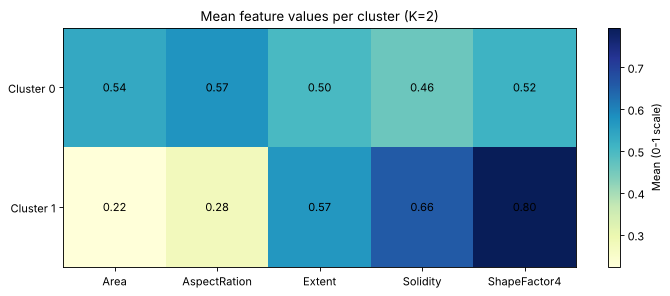

In [30]:
features = ["Area", "AspectRation", "Extent", "Solidity", "ShapeFactor4"]
best_labels = kmeans_labels[best_k]

profile = df[features].groupby(best_labels).mean().round(3)
profile.index.name = "Cluster"
profile["Size"] = np.bincount(best_labels)
display(profile)

fig, ax = plt.subplots(figsize=(9, 3 + best_k * 0.4))
im = ax.imshow(profile[features].values, cmap="YlGnBu", aspect="auto")
ax.set_xticks(range(len(features)))
ax.set_xticklabels(features)
ax.set_yticks(range(best_k))
ax.set_yticklabels([f"Cluster {c}" for c in range(best_k)])
for i in range(best_k):
    for j in range(len(features)):
        ax.text(j, i, f"{profile[features].values[i, j]:.2f}", ha="center", va="center")
plt.colorbar(im, label="Mean (0-1 scale)")
plt.title(f"Mean feature values per cluster (K={best_k})")
plt.tight_layout()
plt.show()

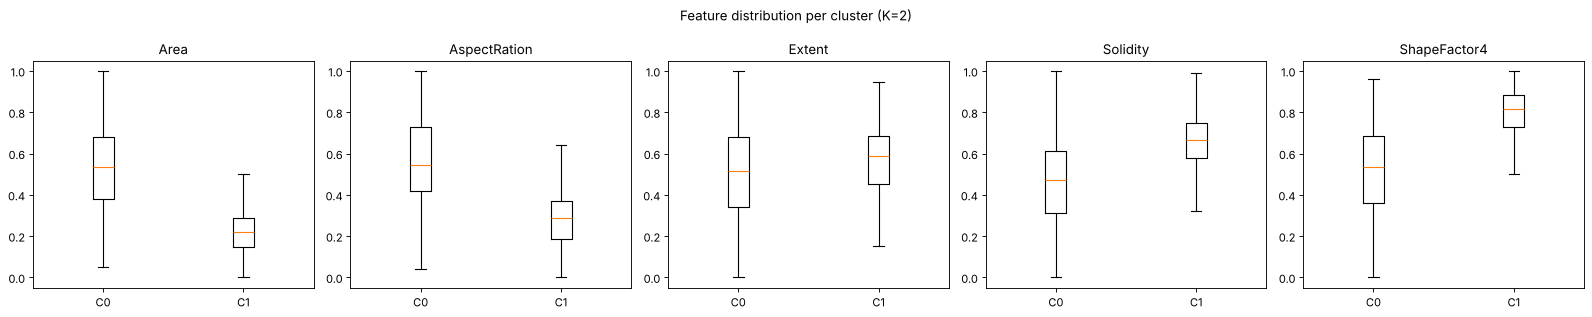

In [31]:
fig, axes = plt.subplots(1, len(features), figsize=(20, 4))
for ax, f in zip(axes, features):
    ax.boxplot([df.loc[best_labels == c, f] for c in range(best_k)], showfliers=False)
    ax.set_xticks(range(1, best_k + 1))
    ax.set_xticklabels([f"C{c}" for c in range(best_k)])
    ax.set_title(f)
plt.suptitle(f"Feature distribution per cluster (K={best_k})")
plt.tight_layout()
plt.show()

### Relationships between the columns inside the clusters

A scatter matrix of the five columns, coloured by cluster, shows which pairs of columns separate the groups and how the columns relate to each other (a random sample of 2,000 beans is plotted for readability).

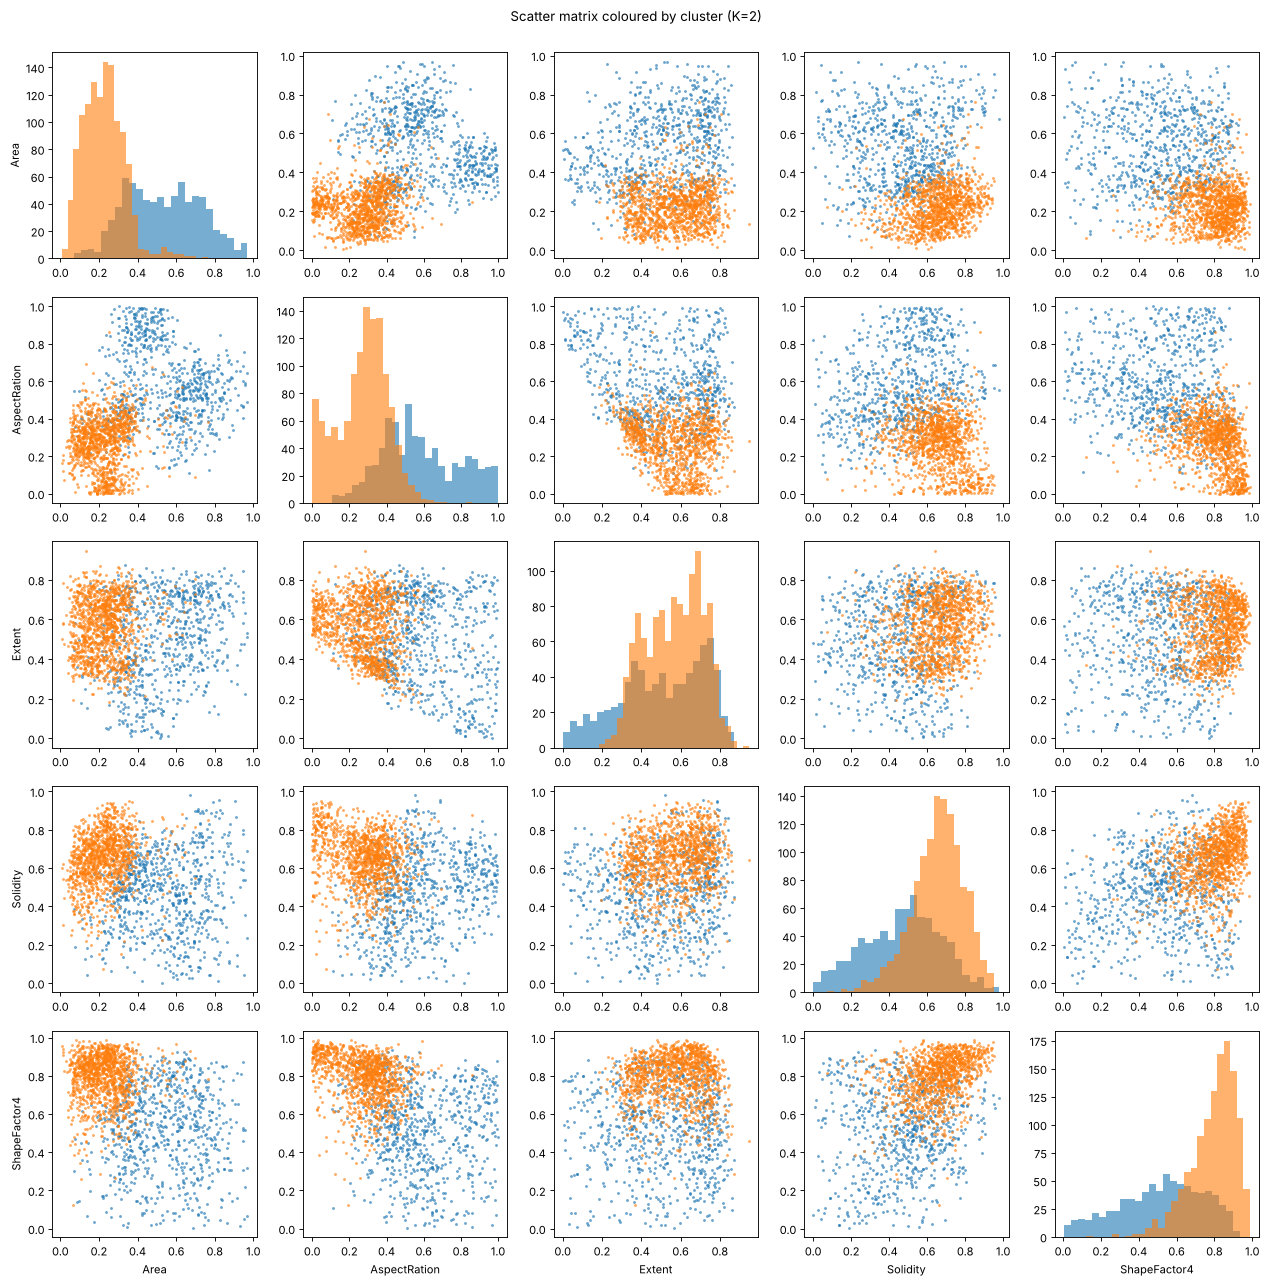

Correlation between the columns:


,Area,AspectRation,Extent,Solidity,ShapeFactor4
Area,1.00,0.44,-0.02,-0.30,-0.46
AspectRation,0.44,1.00,-0.25,-0.23,-0.51
Extent,-0.02,-0.25,1.00,0.17,0.10
Solidity,-0.30,-0.23,0.17,1.00,0.45
ShapeFactor4,-0.46,-0.51,0.10,0.45,1.00


In [32]:
sample_idx = df.sample(2000, random_state=42).index
n = len(features)
fig, axes = plt.subplots(n, n, figsize=(16, 16))
for i, fy in enumerate(features):
    for j, fx in enumerate(features):
        ax = axes[i, j]
        if i == j:
            for c in range(best_k):
                ax.hist(df.loc[sample_idx][best_labels[sample_idx] == c][fx], bins=25, alpha=0.6, color=colors[c])
        else:
            for c in range(best_k):
                pts = df.loc[sample_idx][best_labels[sample_idx] == c]
                ax.scatter(pts[fx], pts[fy], s=3, alpha=0.5, color=colors[c])
        if i == n - 1:
            ax.set_xlabel(fx)
        if j == 0:
            ax.set_ylabel(fy)
plt.suptitle(f"Scatter matrix coloured by cluster (K={best_k})", y=1.0)
plt.tight_layout()
plt.show()

print("Correlation between the columns:")
display(df[features].corr().round(2))

### Clusters vs. the real bean classes

The class label was **not** used for clustering. Comparing the clusters with the real classes afterwards shows whether the groups K-Means found are meaningful.


===== K=2 | Adjusted Rand Index = 0.254 =====


Class,BARBUNYA,CALI,DERMASON,HOROZ,SEKER,SIRA
Cluster,,,,,,
0,944,1178,110,1043,2,744
1,127,47,3353,23,1185,1838



===== K=3 | Adjusted Rand Index = 0.260 =====


Class,BARBUNYA,CALI,DERMASON,HOROZ,SEKER,SIRA
Cluster,,,,,,
0,84,34,3102,16,1180,1465
1,695,1036,34,433,2,333
2,292,155,327,617,5,784



===== K=4 | Adjusted Rand Index = 0.276 =====


Class,BARBUNYA,CALI,DERMASON,HOROZ,SEKER,SIRA
Cluster,,,,,,
0,93,102,368,542,6,756
1,795,391,69,58,8,220
2,117,719,12,454,1,253
3,66,13,3014,12,1172,1353


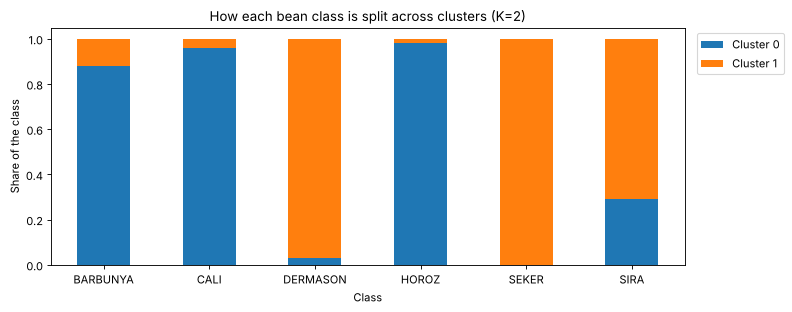

In [33]:
from sklearn.metrics import adjusted_rand_score

for k in k_values:
    ct = pd.crosstab(kmeans_labels[k], df["Class"], rownames=["Cluster"], colnames=["Class"])
    print(f"\n===== K={k} | Adjusted Rand Index = {adjusted_rand_score(df['Class'], kmeans_labels[k]):.3f} =====")
    display(ct)

ct_best = pd.crosstab(best_labels, df["Class"], normalize="columns").round(2)
ax = ct_best.T.plot(kind="bar", stacked=True, figsize=(10, 4), color=colors[:best_k])
ax.set_ylabel("Share of the class")
ax.set_title(f"How each bean class is split across clusters (K={best_k})")
ax.legend([f"Cluster {c}" for c in range(best_k)], bbox_to_anchor=(1.01, 1), loc="upper left")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 8. Interpretation of the results for each K

| | K=2 | K=3 | K=4 |
|---|---:|---:|---:|
| Average Silhouette width | **0.3370** | 0.3031 | 0.2938 |
| Total within-cluster sum of square | 35522.56 | 30538.48 | **26911.59** |
| Calinski–Harabasz index (higher is better) | **5202.42** | 3889.82 | 3418.10 |

**K = 2.** The data splits into two clear groups. **Cluster 0** (≈4,000 beans) has large **Area** (≈0.54), high **AspectRation** (≈0.57) and low **Solidity / ShapeFactor4** — large, elongated beans. It contains almost all **CALI, HOROZ and BARBUNYA** beans. **Cluster 1** (≈6,570 beans) has small Area (≈0.22), low AspectRation (≈0.28) and high Solidity / ShapeFactor4 — small, round, compact beans. It contains almost all **DERMASON and SEKER** beans and most **SIRA**. This K has the highest silhouette and the highest Calinski–Harabasz index, so the clusters are the most compact and best separated. The only mixed class is SIRA (about 30% falls in cluster 0), because SIRA is medium-sized.

**K = 3.** The small-round group stays the same (cluster 0: DERMASON, SEKER, most SIRA). The large-bean group is divided into: cluster 1 — large beans with high Extent (mostly **CALI** and **BARBUNYA**), and cluster 2 — medium-to-large elongated beans with very **low Extent** (≈0.30; HOROZ, SIRA, BARBUNYA mixed). The silhouette drops to 0.303 because cluster 2 overlaps with both other clusters.

**K = 4.** WCSS is lowest (expected, since WCSS always decreases as K grows), but the silhouette is the lowest (0.294). The large-bean group is split further into a low-Solidity cluster (BARBUNYA-dominant) and a high-AspectRation cluster (CALI and HOROZ), while the small-round cluster stays unchanged. Extra clusters improve compactness only slightly and create more overlap.

**Best K.** The votes are: Silhouette → **K = 2**, Calinski–Harabasz → **K = 2**, Elbow (KneeLocator) → **K = 3**. Two of the three methods choose K = 2, so by the majority rule **K = 2 is the optimal number of clusters**. The elbow points to K = 3 because WCSS still drops noticeably from 2 to 3 (−4,984) and then flattens; however, the silhouette shows that this third cluster overlaps with the other two. Note that a higher K always gives a lower WCSS, so WCSS alone is not a reason to choose a larger K.

**Relationships between the columns.** Area and AspectRation increase together, while Solidity and ShapeFactor4 are higher for small round beans. **Area, AspectRation and ShapeFactor4** are the columns that separate the clusters most clearly; Extent mainly separates the third cluster when K = 3.

## 9. Comparison with the research paper

The selected paper (Khan *et al.*, 2023 [1]) studies the same UCI Dry Bean dataset [2] but applies **only classification** (LR, NB, KNN, DT, RF, XGB, SVM, MLP); it does not report any clustering results. The comparison is therefore made on the points the two studies share:

| Point | Research paper [1] | Our project |
|---|---|---|
| Classes | 7 (incl. BOMBAY) | 6 (BOMBAY removed during preprocessing) |
| Features | 16 | 5 (after feature selection) |
| Outliers | Removed with IQR | Removed during preprocessing |
| Decision Tree accuracy | ≈90% (with and without ADASYN) | ≈86.7–87.4% (Entropy and Gini) |
| Clustering | Not applied | K-Means, best K = 2 (Silhouette 0.337) |

- **Classification:** our Decision Tree accuracy (best 87.36%, Entropy 90/10) is close to the paper's DT accuracy (90%). The small difference is reasonable because we used only 5 of the 16 features.
- **Clustering and the paper's findings:** the paper reports that size- and shape-related features (ShapeFactor2, MinorAxisLength, ShapeFactor1, EquivDiameter, Roundness, ConvexArea) are the most important for separating bean types. Our clustering agrees: without using the labels, K-Means separated the beans mainly by **size (Area)** and **shape (AspectRation, ShapeFactor4)**.
- **Hard classes:** the paper reports SIRA as the class with the lowest accuracy (≈85% with XGB) and notes confusion between similar classes. In our clustering, SIRA is also the class that is split across clusters, which confirms that SIRA beans share characteristics with both small (DERMASON) and larger beans.
- **Why clustering alone cannot recover all 6 classes:** the Adjusted Rand Index is low (≈0.25–0.28) for all K, because several classes have very similar shapes. This explains why the paper needed supervised models with many features to reach high accuracy.

# [7] Findings and Discussion

## Classification Findings

### Comparison of the Results

Two attribute selection measures (Entropy and Gini index) were tested on three different data partitions. The following table compares their accuracy:

| Data Split | Entropy Accuracy | Gini Accuracy | Higher Accuracy |
|---|---:|---:|---|
| 90/10 | 87.36% | 86.51% | Entropy |
| 80/20 | 86.17% | 87.07% | Gini |
| 70/30 | 86.88% | 86.47% | Entropy |
| Average | 86.80% | 86.68% | Entropy |

### Best Model

The best-performing model is the **Decision Tree with Entropy and a 90/10 split**, which achieved an accuracy of approximately **87.36%**. Entropy also achieved a slightly higher average accuracy than Gini (**86.80%** compared with **86.68%**). However, all six models achieved accuracies between **86.17%** and **87.36%**, so the difference between the two measures is small, and both give a stable accuracy of about 86–87% on this dataset.

### How the Classification Is Achieved

In the final tree, **Area** is the root node, followed by **AspectRation**, **Solidity** and **ShapeFactor4**. This shows that bean size and shape are the main attributes used to separate the bean types.

### Is the Result Meaningful?

Yes. About **87%** of the beans are classified correctly using only five measurements, and the tree gives clear rules based on size and shape.

## Clustering Findings

### Comparison of the Results

K-Means was applied to the five standardized attributes (without the class label) using K = 2, 3 and 4. The following table compares the average silhouette width and the total within-cluster sum of squares (WCSS) for each K:

| | K = 2 | K = 3 | K = 4 |
|---|---:|---:|---:|
| Average silhouette width | 0.3370 | 0.3031 | 0.2938 |
| Total within-cluster sum of squares | 35,522.56 | 30,538.48 | 26,911.59 |

### Best K

By the majority rule, the best number of clusters is **K = 2**. The silhouette width and the Calinski–Harabasz index both choose K = 2, while the Elbow method (KneeLocator) chooses K = 3. The WCSS always decreases when K increases, so it cannot be used alone to choose K. The silhouette values are low for all K (below 0.35), which means that the clusters overlap and the beans do not form sharply separated groups.

### What the Clusters Represent (K = 2)

The two clusters are separated mainly by bean size and shape:

- **Cluster 0 (4,021 beans):** large and elongated beans (high Area **0.54** and AspectRation **0.57**, low Solidity **0.46** and ShapeFactor4 **0.52**). It contains most of the CALI (1,178), BARBUNYA (944) and HOROZ (1,043) beans.
- **Cluster 1 (6,573 beans):** small, round and compact beans (low Area **0.22** and AspectRation **0.28**, high Solidity **0.66** and ShapeFactor4 **0.80**). It contains most of the DERMASON (3,353), SEKER (1,185) and SIRA (1,838) beans.

SIRA is the only class that is clearly split between the two clusters (744 of its 2,582 beans fall in Cluster 0), because SIRA beans are medium-sized.

### Is the Result Meaningful?

Yes, as a size and shape grouping. The two clusters separate small, round beans from large, elongated beans, which is consistent with the classification results, where bean size and shape (**Area** and **AspectRation**) are also the main attributes used by the Decision Tree.

### Discussion Based on the Research Paper

The research paper [1] uses the same Dry Bean dataset, but it applies classification only. Its Decision Tree reaches about 90% accuracy, and its best model, XGBoost, reaches 93.0% (95.4% with ADASYN). Our Decision Tree models reach between 86.17% and 87.36%, and the best one is Entropy 90/10 with 87.36%.

The difference is mainly because the paper uses all 16 features and 7 classes, while we use 5 features and 6 classes (the BOMBAY class was removed with the outliers). Both the paper and our work use the IQR method to handle outliers.

The paper does not apply clustering, so the clustering results cannot be compared with it.

### Problem Solutions and Extracted Information

**Classification:** The Decision Tree identifies the bean type with about 87% accuracy, using mainly Area, then AspectRation, Solidity and ShapeFactor4.

**Clustering:** K-Means with K = 2 separates the beans into large and elongated beans (mostly CALI, BARBUNYA and HOROZ) and small, round and compact beans (mostly DERMASON, SEKER and SIRA).

# [8] References

[1] M. S. Khan, T. D. Nath, M. M. Hossain, A. Mukherjee, H. B. Hasnath, T. M. Meem, and U. Khan, “Comparison of multiclass classification techniques using dry bean dataset,” *International Journal of Cognitive Computing in Engineering*, vol. 4, pp. 6–20, 2023, doi: 10.1016/j.ijcce.2023.01.002.

[2] UCI Machine Learning Repository, “Dry Bean Dataset.” [Online]. Available: https://archive.ics.uci.edu/dataset/602/dry+bean+dataset. [Accessed: Nov. 5, 2026].